In [74]:
import numpy as np
import pandas as pd

import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [ ]:
##===========================================================Dataset Load And Check===============================================================

In [112]:
df = pd.read_csv("college_student_placement_dataset.csv")
df

,College_ID,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
0,CLG0030,107,6.61,6.28,8,No,8,8,4,No
1,CLG0061,97,5.52,5.37,8,No,7,8,0,No
2,CLG0036,109,5.36,5.83,9,No,3,1,1,No
3,CLG0055,122,5.47,5.75,6,Yes,1,6,1,No
4,CLG0004,96,7.91,7.69,7,No,8,10,2,No
...,...,...,...,...,...,...,...,...,...,...
9995,CLG0021,119,8.41,8.29,4,No,1,8,0,Yes
9996,CLG0098,70,9.25,9.34,7,No,0,7,2,No
9997,CLG0066,89,6.08,6.25,3,Yes,3,9,5,No
9998,CLG0045,107,8.77,8.92,3,No,7,5,1,No


In [3]:
df.head()

,College_ID,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
0,CLG0030,107,6.61,6.28,8,No,8,8,4,No
1,CLG0061,97,5.52,5.37,8,No,7,8,0,No
2,CLG0036,109,5.36,5.83,9,No,3,1,1,No
3,CLG0055,122,5.47,5.75,6,Yes,1,6,1,No
4,CLG0004,96,7.91,7.69,7,No,8,10,2,No


In [4]:
df.tail()

,College_ID,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
9995,CLG0021,119,8.41,8.29,4,No,1,8,0,Yes
9996,CLG0098,70,9.25,9.34,7,No,0,7,2,No
9997,CLG0066,89,6.08,6.25,3,Yes,3,9,5,No
9998,CLG0045,107,8.77,8.92,3,No,7,5,1,No
9999,CLG0060,109,9.41,9.77,8,No,3,5,5,No


In [5]:
df.isnull().sum(
    
)

College_ID                0
IQ                        0
Prev_Sem_Result           0
CGPA                      0
Academic_Performance      0
Internship_Experience     0
Extra_Curricular_Score    0
Communication_Skills      0
Projects_Completed        0
Placement                 0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.shape

(10000, 10)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   College_ID              10000 non-null  object 
 1   IQ                      10000 non-null  int64  
 2   Prev_Sem_Result         10000 non-null  float64
 3   CGPA                    10000 non-null  float64
 4   Academic_Performance    10000 non-null  int64  
 5   Internship_Experience   10000 non-null  object 
 6   Extra_Curricular_Score  10000 non-null  int64  
 7   Communication_Skills    10000 non-null  int64  
 8   Projects_Completed      10000 non-null  int64  
 9   Placement               10000 non-null  object 
dtypes: float64(2), int64(5), object(3)
memory usage: 781.4+ KB


In [11]:
df.describe()

,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Extra_Curricular_Score,Communication_Skills,Projects_Completed
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,99.471800,7.535673,7.532379,5.546400,4.970900,5.561800,2.513400
std,15.053101,1.447519,1.470141,2.873477,3.160103,2.900866,1.715959
min,41.000000,5.000000,4.540000,1.000000,0.000000,1.000000,0.000000
25%,89.000000,6.290000,6.290000,3.000000,2.000000,3.000000,1.000000
50%,99.000000,7.560000,7.550000,6.000000,5.000000,6.000000,3.000000
75%,110.000000,8.790000,8.770000,8.000000,8.000000,8.000000,4.000000
max,158.000000,10.000000,10.460000,10.000000,10.000000,10.000000,5.000000


In [13]:
df.columns

Index(['College_ID', 'IQ', 'Prev_Sem_Result', 'CGPA', 'Academic_Performance',
       'Internship_Experience', 'Extra_Curricular_Score',
       'Communication_Skills', 'Projects_Completed', 'Placement'],
      dtype='object')

In [18]:
df.dtypes

College_ID                 object
IQ                          int64
Prev_Sem_Result           float64
CGPA                      float64
Academic_Performance        int64
Internship_Experience      object
Extra_Curricular_Score      int64
Communication_Skills        int64
Projects_Completed          int64
Placement                  object
dtype: object

In [19]:
df.nunique()

College_ID                100
IQ                        104
Prev_Sem_Result           501
CGPA                      590
Academic_Performance       10
Internship_Experience       2
Extra_Curricular_Score     11
Communication_Skills       10
Projects_Completed          6
Placement                   2
dtype: int64

In [ ]:
##==========================================================EDA=========================================================================

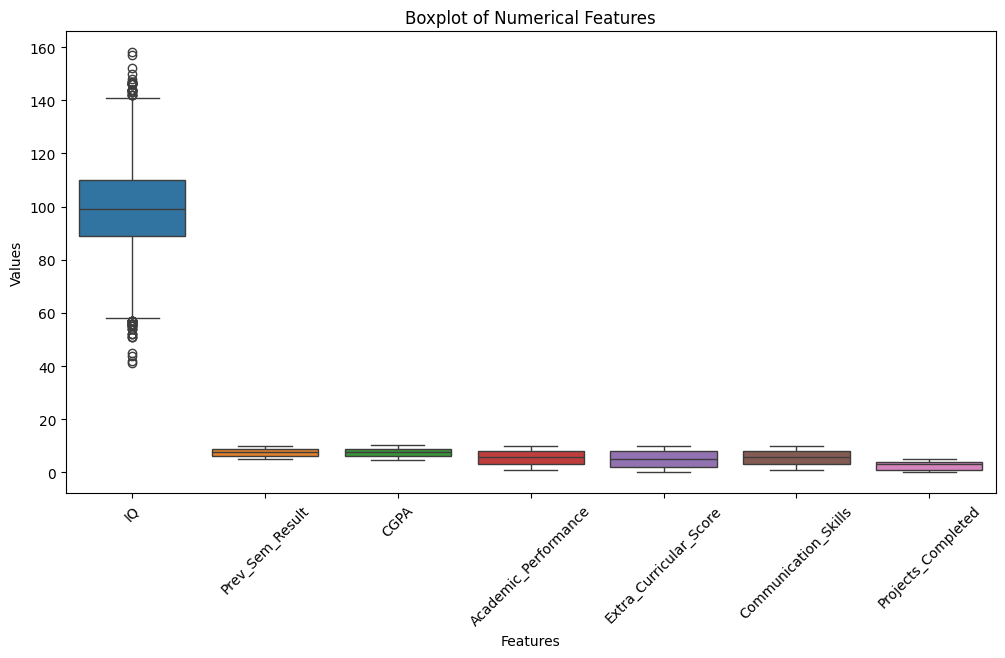

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.boxplot(data=df.select_dtypes(include=np.number))

plt.xticks(rotation=45)
plt.title("Boxplot of Numerical Features")
plt.xlabel("Features")
plt.ylabel("Values")

plt.show()

<Figure size 700x800 with 0 Axes>

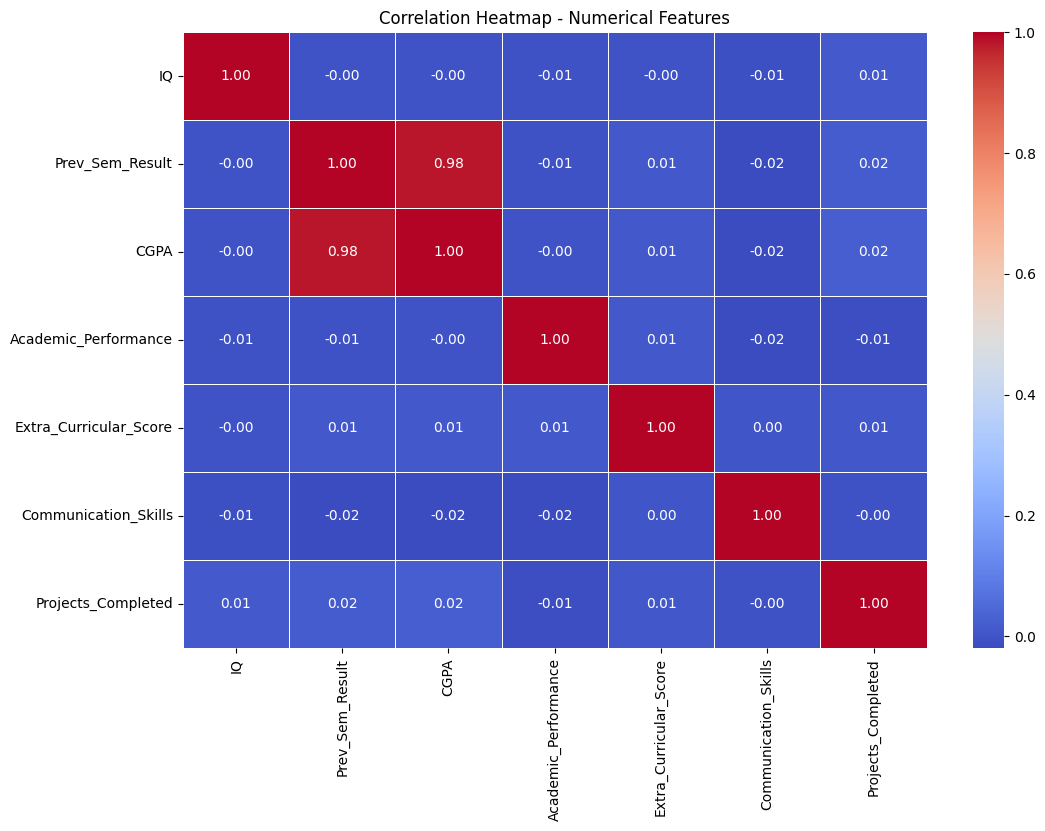

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap - Numerical Features")
plt.show()

In [ ]:
##===========================================================Encoding===================================================================

In [113]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

df["Internship_Experience"] = encoder.fit_transform(
    df["Internship_Experience"]
)
df

,College_ID,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
0,CLG0030,107,6.61,6.28,8,0,8,8,4,No
1,CLG0061,97,5.52,5.37,8,0,7,8,0,No
2,CLG0036,109,5.36,5.83,9,0,3,1,1,No
3,CLG0055,122,5.47,5.75,6,1,1,6,1,No
4,CLG0004,96,7.91,7.69,7,0,8,10,2,No
...,...,...,...,...,...,...,...,...,...,...
9995,CLG0021,119,8.41,8.29,4,0,1,8,0,Yes
9996,CLG0098,70,9.25,9.34,7,0,0,7,2,No
9997,CLG0066,89,6.08,6.25,3,1,3,9,5,No
9998,CLG0045,107,8.77,8.92,3,0,7,5,1,No


In [ ]:
##==========================================================Feature Selection==================================================================

In [114]:
df.drop(columns=["College_ID"], inplace=True)

In [ ]:
##==========================================================Corrilation Feature Selection=======================================================

In [37]:
corrilation_matrix = df.corr(numeric_only=True)
corrilation_matrix

,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed
IQ,1.000000,-0.002640,-0.002859,-0.006827,-0.000247,-0.003458,-0.010896,0.014538
Prev_Sem_Result,-0.002640,1.000000,0.980768,-0.005765,-0.013347,0.009326,-0.017269,0.018434
CGPA,-0.002859,0.980768,1.000000,-0.002958,-0.012562,0.011441,-0.018242,0.020872
Academic_Performance,-0.006827,-0.005765,-0.002958,1.000000,0.025903,0.011774,-0.019733,-0.013148
Internship_Experience,-0.000247,-0.013347,-0.012562,0.025903,1.000000,0.002093,-0.020437,-0.010260
Extra_Curricular_Score,-0.003458,0.009326,0.011441,0.011774,0.002093,1.000000,0.003769,0.008122
Communication_Skills,-0.010896,-0.017269,-0.018242,-0.019733,-0.020437,0.003769,1.000000,-0.004486
Projects_Completed,0.014538,0.018434,0.020872,-0.013148,-0.010260,0.008122,-0.004486,1.000000


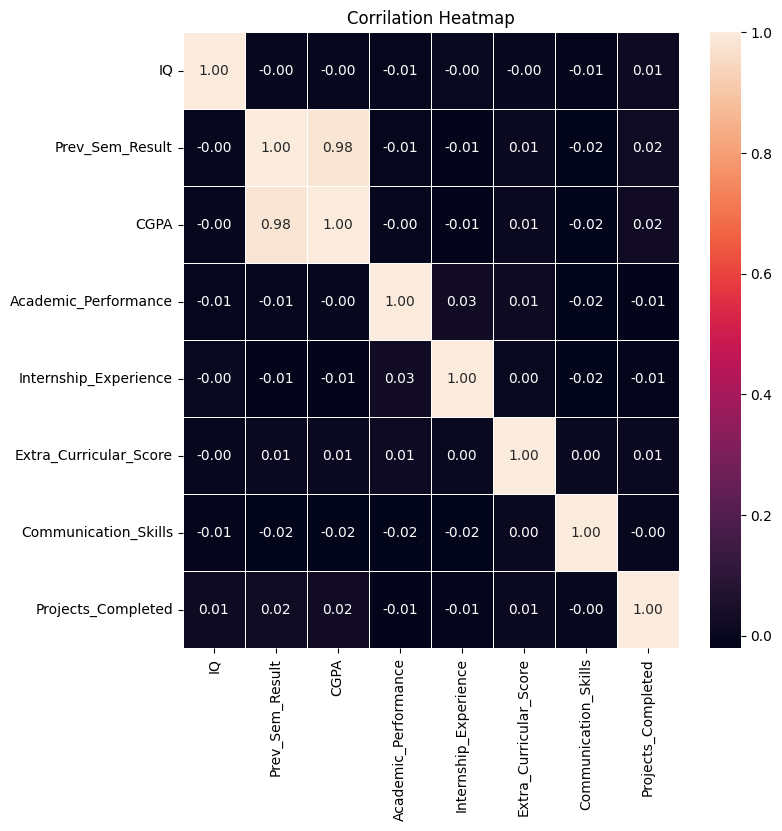

In [40]:
plt.figure(figsize=(8,8))

sns.heatmap(
    corrilation_matrix,
    annot=True,
    fmt=".2f",
    linewidths=0.5
)
plt.title("Corrilation Heatmap")
plt.show()

In [44]:
upper_trangle = corrilation_matrix.where(
    np.triu(np.ones(corrilation_matrix.shape),k=1).astype(bool)
)

upper_trangle

,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed
IQ,NaN,-0.00264,-0.002859,-0.006827,-0.000247,-0.003458,-0.010896,0.014538
Prev_Sem_Result,NaN,NaN,0.980768,-0.005765,-0.013347,0.009326,-0.017269,0.018434
CGPA,NaN,NaN,NaN,-0.002958,-0.012562,0.011441,-0.018242,0.020872
Academic_Performance,NaN,NaN,NaN,NaN,0.025903,0.011774,-0.019733,-0.013148
Internship_Experience,NaN,NaN,NaN,NaN,NaN,0.002093,-0.020437,-0.010260
Extra_Curricular_Score,NaN,NaN,NaN,NaN,NaN,NaN,0.003769,0.008122
Communication_Skills,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.004486
Projects_Completed,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [45]:
drop_one = [
    columns
    for columns in upper_trangle
    if any(upper_trangle[columns]>0.85)
]

drop_one

['CGPA']

In [36]:
df

,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
0,107,6.61,6.28,8,0,8,8,4,No
1,97,5.52,5.37,8,0,7,8,0,No
2,109,5.36,5.83,9,0,3,1,1,No
3,122,5.47,5.75,6,1,1,6,1,No
4,96,7.91,7.69,7,0,8,10,2,No
...,...,...,...,...,...,...,...,...,...
9995,119,8.41,8.29,4,0,1,8,0,Yes
9996,70,9.25,9.34,7,0,0,7,2,No
9997,89,6.08,6.25,3,1,3,9,5,No
9998,107,8.77,8.92,3,0,7,5,1,No


In [ ]:
##==============================================================RFE=========================================================================

In [49]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression


x = df.drop(columns=["Placement"])
y = df["Placement"]

x_train,x_test,y_train,y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

model = LogisticRegression(
    max_iter=1000
)

rfe = RFE(
    estimator=model,
    n_features_to_select=4
)

rfe.fit(x_train,y_train)

selected_features = x_train.columns[rfe.support_]

print("Selected Features: ")
selected_features

Selected Features: 


Index(['Prev_Sem_Result', 'CGPA', 'Communication_Skills',
       'Projects_Completed'],
      dtype='object')

In [ ]:
##===============================================================Mutual Information========================================================

In [50]:
from sklearn.feature_selection import mutual_info_classif

mi = mutual_info_classif(
    x,
    y,
    random_state=42
)

mi_score = pd.DataFrame({
    "Features":x.columns,
    "MI Score":mi
})

mi_score.sort_values(
    by="MI Score",
    ascending=False
)

mi_score

,Features,MI Score
0,IQ,0.065762
1,Prev_Sem_Result,0.064915
2,CGPA,0.070061
3,Academic_Performance,0.000000
4,Internship_Experience,0.000000
5,Extra_Curricular_Score,0.000000
6,Communication_Skills,0.076192
7,Projects_Completed,0.043411


In [ ]:
##===========================================================Tree Model Selection==========================================================

In [52]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel

model = RandomForestClassifier(n_estimators=200, random_state=42)
model.fit(x_train, y_train)

selector = SelectFromModel(model, threshold="median")

x_train_selected = selector.transform(x_train)
x_test_selected = selector.transform(x_test)

print("Selected Features:", x_train.columns[selector.get_support()])

Selected Features: Index(['IQ', 'CGPA', 'Communication_Skills', 'Projects_Completed'], dtype='object')


In [ ]:
##========================================================Finally Selected Features==========================================================

In [116]:
df.drop(columns=["Prev_Sem_Result","Academic_Performance","Internship_Experience","Extra_Curricular_Score"],inplace=True)
df

,IQ,CGPA,Communication_Skills,Projects_Completed,Placement
0,107,6.28,8,4,No
1,97,5.37,8,0,No
2,109,5.83,1,1,No
3,122,5.75,6,1,No
4,96,7.69,10,2,No
...,...,...,...,...,...
9995,119,8.29,8,0,Yes
9996,70,9.34,7,2,No
9997,89,6.25,9,5,No
9998,107,8.92,5,1,No


In [117]:
df

,IQ,CGPA,Communication_Skills,Projects_Completed,Placement
0,107,6.28,8,4,No
1,97,5.37,8,0,No
2,109,5.83,1,1,No
3,122,5.75,6,1,No
4,96,7.69,10,2,No
...,...,...,...,...,...
9995,119,8.29,8,0,Yes
9996,70,9.34,7,2,No
9997,89,6.25,9,5,No
9998,107,8.92,5,1,No


In [ ]:
##============================================================Train Test Split============================================================

In [119]:
print(df.columns.tolist())

['IQ', 'CGPA', 'Communication_Skills', 'Projects_Completed', 'Placement']


In [120]:
x = df.drop(columns=["Placement"])
y = df["Placement"]

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
##==========================================================Model Training==================================================================

In [ ]:
##==========================================================Logistic Regression============================================================

In [78]:
print(df.columns.tolist())

['College_ID', 'IQ', 'Prev_Sem_Result', 'CGPA', 'Academic_Performance', 'Internship_Experience', 'Extra_Curricular_Score', 'Communication_Skills', 'Projects_Completed', 'Placement']


In [125]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()

x_train_scaler = scaler.fit_transform(x_train)
x_test_scaler = scaler.transform(x_test)

model = LogisticRegression(max_iter=1000)
model.fit(x_train_scaler, y_train)

y_pred = model.predict(x_test_scaler)


iq = float(input("Enter The Student IQ Level: "))
cgpa = float(input("Enter The Student CGPA: "))
cmp = float(input("Enter The Communication Skill: "))
prjc = float(input("Enter The Completed Projects: "))

new_df = pd.DataFrame({
    "IQ": [iq],
    "CGPA": [cgpa],
    "Communication_Skills": [cmp],
    "Projects_Completed": [prjc]
})

new_df = scaler.transform(new_df)

prediction = model.predict(new_df)
print()
print(f"Placement Status Is:  {prediction[0]}")

print("-"*50)

print(f"Accuracy Score Is:  {accuracy_score(y_test,y_pred)}")
print(f"Confusion Matrix:   {confusion_matrix(y_test,y_pred)}")

print("\n")

print(f"Classification Report: \n{classification_report(y_test,y_pred)}")

Enter The Student IQ Level:  200
Enter The Student CGPA:  7.79
Enter The Communication Skill:  8
Enter The Completed Projects:  20



Placement Status Is:  Yes
--------------------------------------------------
Accuracy Score Is:  0.9025
Confusion Matrix:   [[1608   66]
 [ 129  197]]


Classification Report: 
              precision    recall  f1-score   support

          No       0.93      0.96      0.94      1674
         Yes       0.75      0.60      0.67       326

    accuracy                           0.90      2000
   macro avg       0.84      0.78      0.81      2000
weighted avg       0.90      0.90      0.90      2000



In [ ]:
##===================================================================KNN======================================================================

In [ ]:
from sklearn.neighbors import KNeighborsClassifier


scaler = StandardScaler()

x_train_scaler = scaler.fit_transform(x_train)
x_test_scaler = scaler.transform(x_test)


model = KNeighborsClassifier(n_neighbors=5)

model.fit(x_train_scaler,y_train)

y_pred = model.predict(x_test_scaler)


iq = float(input("Enter The Student IQ Lavel: "))
cgpa = float(input("Enter The Student CGPA: "))
cms = float(input("Enter The Communication Skill Score: "))
prjc = float(input("Enter The Compleated Projects: "))


new_df = pd.DataFrame({
    "IQ":[iq],
    "CGPA":[cgpa],
    "Communication_Skills":[cms],
    "Projects_Completed":[prjc]
})
print()
new_df = scaler.transform(new_df)

prediction = model.predict(new_df)
print("-"*50)

print(f"The Placement Status Is:  {prediction[0]}")

print()

print(f"Accuracy Score Is:  {accuracy_score(y_test,y_pred)}")
print(f"Confusion Matrix:   {confusion_matrix(y_test,y_pred)}")
print("\n")

print(f"Classification Report:   \n{classification_report(y_test,y_pred)}")

In [ ]:
##========================================================Overall Status=====================================================================